<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture design](README.md)

# 01 · Which credential metadata belongs in the expiry review queue?

An inventory's “days until expiry” value is a snapshot of a clock. It does not keep counting down after the result is saved. How should we build a repeatable review queue while keeping credentials with missing expiry dates visible?

We will read **synthetic application and service-principal metadata through the real Governance VGI functions**, retain the full inventory, and classify exact expiry timestamps against an explicit UTC audit date. The published release verifies the schema; a fixture harness injects the repository's shipped fake client into the original functions. **No Azure tenant is contacted, and no secret values are present.**

## Choose the audit date and horizon

`AS_OF_UTC` is an explicit audit instant, not the computer's clock. `HORIZON_DAYS` means elapsed 24-hour days, from 0 to 180. A known expiry strictly before the audit instant is **past due**; an expiry in the **closed interval** `[AS_OF_UTC, AS_OF_UTC + HORIZON_DAYS]` is **due in horizon**. Missing dates form their own category.

The final experiment changes only **30 → 60 days**. Keep the audit date fixed, then restart the kernel and run all. The fixture was designed around 2026-11-14 UTC; changing the audit date is a different investigation.

In [1]:
HORIZON_DAYS = 30  # Integer 0–180, elapsed 24-hour days; experiment: 60
AS_OF_UTC = "2026-11-14T00:00:00Z"  # Explicit timezone-aware audit instant

In [2]:
import hashlib
import json
import os
import tempfile
from datetime import datetime, timezone
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert isinstance(HORIZON_DAYS,int) and not isinstance(HORIZON_DAYS,bool) and 0 <= HORIZON_DAYS <= 180
as_of=datetime.fromisoformat(AS_OF_UTC.replace("Z","+00:00"))
assert as_of.tzinfo is not None, "AS_OF_UTC needs an explicit timezone"
AS_OF_UTC=as_of.astimezone(timezone.utc).isoformat()
fixture_bytes=Path("fixture.json").read_bytes()
fixture_hash=hashlib.sha256(fixture_bytes).hexdigest()
scratch=tempfile.TemporaryDirectory(prefix="vgi-governance-notebook-")
trace_path=Path(scratch.name)/"fetches.jsonl";trace_path.write_text("")
os.environ["VGI_GOVERNANCE_FIXTURE_TRACE"]=str(trace_path)
os.environ["PLOOMBER_STATS_ENABLED"]="false"
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams.update({"figure.dpi":125,"text.parse_math":False,"axes.spines.top":False,"axes.spines.right":False})
STATES=["Past due","Due in horizon","Later","No declared expiry"]
COLORS={"Past due":"#ad4336","Due in horizon":"#b88a29","Later":"#247f9e","No declared expiry":"#858585"}
def prose(text):display(Markdown(text))
def finish(fig):
    fig.text(.01,.01,f"Source: synthetic fixture.json · real Governance v0.4.0 functions · audit {as_of:%Y-%m-%d %H:%M UTC}",fontsize=8,color="#555555")
    fig.tight_layout(rect=(0,.05,1,.95));plt.show()
fixture_secret_directory = tempfile.TemporaryDirectory(prefix="vgi-fixture-secrets-")
con = haybarn.connect(config={"secret_directory": fixture_secret_directory.name, "allow_persistent_secrets": False})
assert con.execute("SELECT name, persistent, storage FROM duckdb_secrets()").fetchall() == [], "Fixture must start without SQL secrets"
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline


/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-governance/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-governance/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-governance/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-governance/notebooks/pyproject.toml.

## Verify the release, then attach the declared fixture

The first location is the published v0.4.0 worker. The companion's literal command fetches the **same tag's immutable source commit**, installs its frozen Bun dependencies and imports the original function/catalog factories. It injects `makeFakeGraph` from the repository's tests. Production pagination, flattening, schemas and scan-time expiry calculations execute unchanged.

The visibly dummy secret below satisfies the function's secret lookup. The fixture ignores it, disables runtime network fetch, rejects POST and supports only the credential endpoints. It does not test MSAL, live Graph permissions or service behavior.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'azure' AS published (
    TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-azure-governance@v0.4.0'
);
ATTACH 'azure' AS fixture (
    TYPE vgi,
    LOCATION 'bun run governance_fixture.ts Query-farm/vgi-azure-governance 118c35d99680fb6c4807c9169e4c2097dec7f999 fixture.json'
);
CREATE TEMPORARY SECRET synthetic_fixture_input (
    TYPE azure_graph,
    TENANT_ID '00000000-0000-0000-0000-000000000000',
    CLIENT_ID '00000000-0000-0000-0000-000000000000',
    CLIENT_SECRET 'synthetic-not-a-credential'
);

,Success


In [4]:
fixture_secrets = con.execute("SELECT name, persistent, storage FROM duckdb_secrets() ORDER BY name").fetchall()
assert fixture_secrets == [('synthetic_fixture_input', False, 'memory')], "Only the public temporary fixture secrets may exist"

In [5]:
%%sql published_schema <<
DESCRIBE SELECT owner_kind,owner_id,credential_key_id,end_date_time,days_until_expiry
FROM published.main.app_credentials();

In [6]:
display(published_schema)
prose(f"**Synthetic fixture SHA-256:** `{fixture_hash}`. Schema discovery uses the native release without fetching tenant data. "
      "This is a full-pull snapshot function: it has no cursor or marker row. Refresh a stored inventory by replacing the complete snapshot, not appending repeated copies.")

,column_name,column_type,null,key,default,extra
0,credential_key_id,VARCHAR,YES,None,None,None
1,end_date_time,VARCHAR,YES,None,None,None
2,days_until_expiry,BIGINT,YES,None,None,None


**Synthetic fixture SHA-256:** `469c6d3fa3ee2a8643865e310bad068ae91f20abfbb286b72535f51ff906d3fc`. Schema discovery uses the native release without fetching tenant data. This is a full-pull snapshot function: it has no cursor or marker row. Refresh a stored inventory by replacing the complete snapshot, not appending repeated copies.

## Keep the full inventory and its absolute dates

We deliberately leave `expiring_within_days` unset. That worker filter uses **floored whole days at scan time**, retains already-expired credentials and drops missing expiry dates. It therefore answers a different question from an exact UTC deadline at a fixed audit instant.

Materialize the complete result once. The fixture has two application pages and one service-principal page. Those are separate reads, not an atomic live-directory snapshot; the synthetic fixture itself stays fixed.

In [7]:
SCAN_START_UTC=datetime.now(timezone.utc).isoformat()

In [8]:
%%sql
CREATE TABLE inventory_scan AS
SELECT owner_kind,owner_id,owner_display_name,credential_type,credential_key_id,
       end_date_time,days_until_expiry,is_expired
FROM fixture.main.app_credentials();

CREATE TABLE inventory AS
SELECT *,try_cast(end_date_time AS TIMESTAMPTZ) AS expires_at
FROM inventory_scan;

,Count


In [9]:
SCAN_END_UTC=datetime.now(timezone.utc).isoformat()

In [10]:
%%sql availability <<
SELECT count(*) AS credential_rows,
       count(DISTINCT (owner_kind,owner_id,credential_type,credential_key_id)) AS distinct_credentials,
       count(DISTINCT (owner_kind,owner_id)) AS owners,
       count(*) FILTER (WHERE end_date_time IS NULL) AS missing_expiry,
       count(*) FILTER (WHERE end_date_time IS NOT NULL AND expires_at IS NULL) AS invalid_expiry,
       count(*) FILTER (WHERE expires_at IS NULL AND
                        (days_until_expiry IS NOT NULL OR is_expired IS NOT NULL)) AS inconsistent_nulls,
       count(*) FILTER (WHERE expires_at IS NOT NULL AND
             (days_until_expiry IS NULL OR days_until_expiry < floor(epoch(expires_at-TIMESTAMPTZ '{{SCAN_END_UTC}}')/86400)
              OR days_until_expiry > floor(epoch(expires_at-TIMESTAMPTZ '{{SCAN_START_UTC}}')/86400))) AS clock_mismatches
FROM inventory;

In [11]:
display(availability)
a=availability.iloc[0]
assert a.credential_rows == a.distinct_credentials and a.credential_rows > 0
assert a.invalid_expiry == a.inconsistent_nulls == a.clock_mismatches == 0
requests=[json.loads(line)["url"] for line in trace_path.read_text().splitlines()]
assert any("$skiptoken=PAGE2" in u for u in requests)
prose(f"**Inventory checks passed:** {int(a.credential_rows)} distinct credential records across **{int(a.owners)} owners**; "
      f"**{int(a.missing_expiry)} have no declared expiry**. No invalid timestamps or inconsistent null fields. "
      f"The fixture served **{len(requests)} pages**, including the application nextLink. "
      f"Actual scan interval: **{SCAN_START_UTC}–{SCAN_END_UTC}**. "
      "Returned whole-day counters agree with a clock somewhere inside that interval. We will not reuse them as the audit clock.")

,credential_rows,distinct_credentials,owners,missing_expiry,invalid_expiry,inconsistent_nulls,clock_mismatches
0,12,12,5,2,0,0,0


**Inventory checks passed:** 12 distinct credential records across **5 owners**; **2 have no declared expiry**. No invalid timestamps or inconsistent null fields. The fixture served **3 pages**, including the application nextLink. Actual scan interval: **2026-11-14T10:57:33.778420+00:00–2026-11-14T10:57:33.813207+00:00**. Returned whole-day counters agree with a clock somewhere inside that interval. We will not reuse them as the audit clock.

## Classify against one explicit UTC deadline

SQL recomputes fractional days from `expires_at` to the audit instant and classifies using the **timestamp itself**, avoiding rounding at the horizon boundary. The fixture includes a credential exactly 30 days away and another 30.5 days away so the distinction is visible.

`No declared expiry` is separate from `Later`: an absent date is not evidence that a credential is safe or should be treated as zero days remaining. Owners and credential IDs are synthetic labels; the composite key keeps application and service-principal records distinct.

In [12]:
%%sql
CREATE TABLE classified AS
SELECT *,epoch(expires_at-TIMESTAMPTZ '{{AS_OF_UTC}}')/86400 AS audit_days_remaining,
       CASE WHEN expires_at IS NULL THEN 'No declared expiry'
            WHEN expires_at < TIMESTAMPTZ '{{AS_OF_UTC}}' THEN 'Past due'
            WHEN expires_at <= TIMESTAMPTZ '{{AS_OF_UTC}}'+INTERVAL '{{HORIZON_DAYS}} days' THEN 'Due in horizon'
            ELSE 'Later' END AS review_bucket
FROM inventory;

,Count


In [13]:
%%sql audit_table <<
SELECT owner_id,credential_type,credential_key_id,expires_at,
       days_until_expiry AS worker_scan_whole_days,audit_days_remaining,review_bucket
FROM classified ORDER BY expires_at NULLS LAST,owner_id,credential_key_id;

In [14]:
display(audit_table)
prose("The worker's whole-day count and the audit's fractional-day count intentionally use different clocks. "
      "An exact-deadline queue should compare absolute timestamps. The worker's optional integer-day filter can admit a credential "
      "whose fractional remaining time is greater than its integer threshold because the day count is floored.")

,owner_id,credential_type,credential_key_id,expires_at,worker_scan_whole_days,audit_days_remaining,review_bucket
0,app-a,password,app-a-cred-1,2026-11-08 19:00:00-05:00,-6,-5.000000,Past due
1,sp-a,password,sp-a-cred-1,2026-11-12 19:00:00-05:00,-2,-1.000000,Past due
2,sp-a,key,sp-a-cred-2,2026-11-20 19:00:00-05:00,6,7.000000,Due in horizon
3,app-a,key,app-a-cred-2,2026-11-23 19:00:00-05:00,9,10.000000,Due in horizon
4,app-b,password,app-b-cred-1,2026-12-13 19:00:00-05:00,29,30.000000,Due in horizon
5,app-b,key,app-b-cred-2,2026-12-14 07:00:00-05:00,30,30.500000,Later
6,sp-b,password,sp-b-cred-1,2026-12-28 19:00:00-05:00,44,45.000000,Later
7,app-c,password,app-c-cred-1,2027-01-12 19:00:00-05:00,59,60.000000,Later
8,app-b,password,app-b-cred-3,2027-02-11 19:00:00-05:00,89,90.000000,Later
9,app-c,key,app-c-cred-2,2027-05-12 20:00:00-04:00,179,180.041667,Later


The worker's whole-day count and the audit's fractional-day count intentionally use different clocks. An exact-deadline queue should compare absolute timestamps. The worker's optional integer-day filter can admit a credential whose fractional remaining time is greater than its integer threshold because the day count is floored.

In [15]:
%%sql summary <<
SELECT count(*) AS total,
       count(*) FILTER (WHERE review_bucket='Past due') AS past_due,
       count(*) FILTER (WHERE review_bucket='Due in horizon') AS due_in_horizon,
       count(*) FILTER (WHERE review_bucket='Later') AS later,
       count(*) FILTER (WHERE review_bucket='No declared expiry') AS unknown,
       count(DISTINCT owner_id) FILTER (WHERE review_bucket IN ('Past due','Due in horizon')) AS queue_owners
FROM classified;

In [16]:
%%sql owner_counts <<
SELECT owner_kind,owner_id,owner_display_name,review_bucket,count(*) AS credentials
FROM classified GROUP BY ALL ORDER BY owner_kind,owner_id,review_bucket;

,total,past_due,due_in_horizon,later,unknown,queue_owners
0,12,2,3,5,2,3


At audit **2026-11-14T00:00:00+00:00** with a **30-day** deadline, the dated review queue contains **5 of 12 records** across **3 owners**: 2 past due and 3 due in the horizon. **2 missing-expiry records remain separately visible**; 5 have later known expiries. These counts describe metadata-review workload, not privilege, active use or exposure.

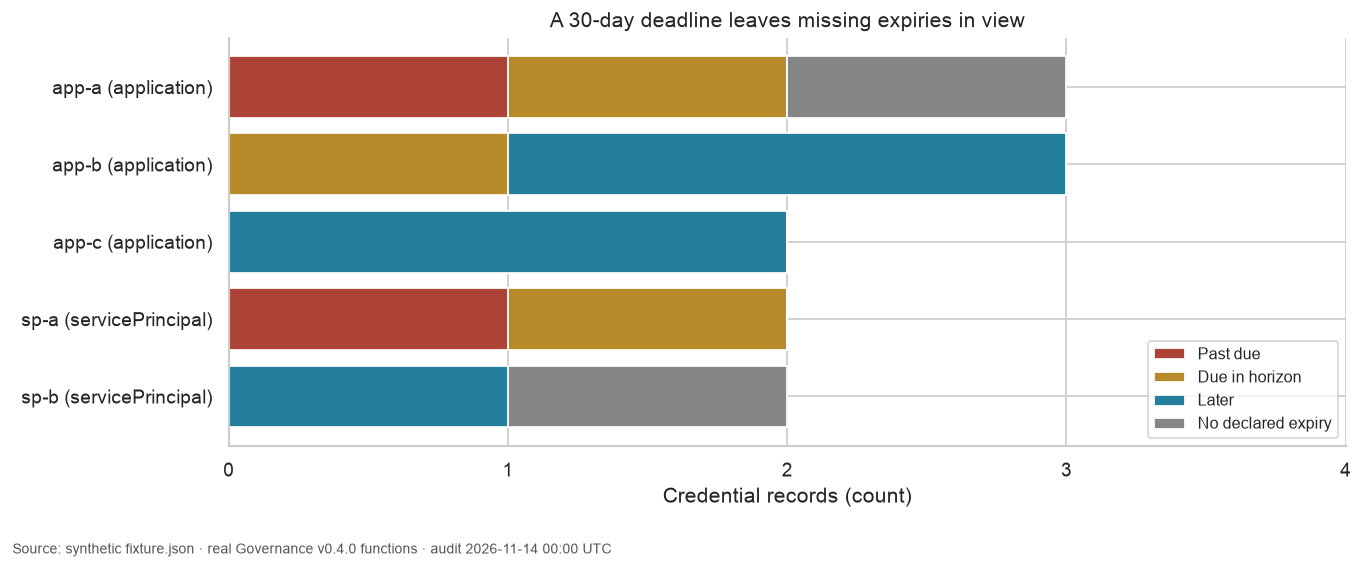

In [17]:
display(summary)
s=summary.iloc[0]
assert s.past_due+s.due_in_horizon+s.later+s.unknown == s.total
queue_count=int(s.past_due+s.due_in_horizon)
prose(f"At audit **{AS_OF_UTC}** with a **{HORIZON_DAYS}-day** deadline, the dated review queue contains "
      f"**{queue_count} of {int(s.total)} records** across **{int(s.queue_owners)} owners**: "
      f"{int(s.past_due)} past due and {int(s.due_in_horizon)} due in the horizon. "
      f"**{int(s.unknown)} missing-expiry records remain separately visible**; {int(s.later)} have later known expiries. "
      "These counts describe metadata-review workload, not privilege, active use or exposure.")
plot=owner_counts.pivot_table(index=["owner_kind","owner_id"],columns="review_bucket",values="credentials",aggfunc="sum",fill_value=0).reindex(columns=STATES,fill_value=0)
fig,ax=plt.subplots(figsize=(11,4.8));left=np.zeros(len(plot));y=np.arange(len(plot))
for state in STATES:
    ax.barh(y,plot[state],left=left,label=state,color=COLORS[state]);left+=plot[state].to_numpy()
ax.set_yticks(y,[f"{owner} ({kind})" for kind,owner in plot.index]);ax.invert_yaxis()
ax.set(xlabel="Credential records (count)",xlim=(0,left.max()+1),title=f"A {HORIZON_DAYS}-day deadline leaves missing expiries in view")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(loc="lower right",fontsize=9);finish(fig)

## How much does a longer horizon add?

The next query evaluates the same materialized inventory at every integer horizon from 0 to 180 days. Past-due records stay in the dated queue; missing expiry dates stay outside it. The threshold comparison remains inclusive at each exact UTC endpoint.

A wider horizon cannot remove records from this fixed inventory's queue. It can increase the number of owners needing review, but it does not establish that each credential must be rotated or that every owner has equal risk.

In [18]:
%%sql sensitivity <<
SELECT days AS horizon_days,
       count(*) FILTER (WHERE expires_at <= TIMESTAMPTZ '{{AS_OF_UTC}}'+days*INTERVAL '1 day') AS dated_queue,
       count(*) FILTER (WHERE expires_at IS NULL) AS missing_expiry
FROM range(0,181) h(days) CROSS JOIN classified
GROUP BY days ORDER BY days;

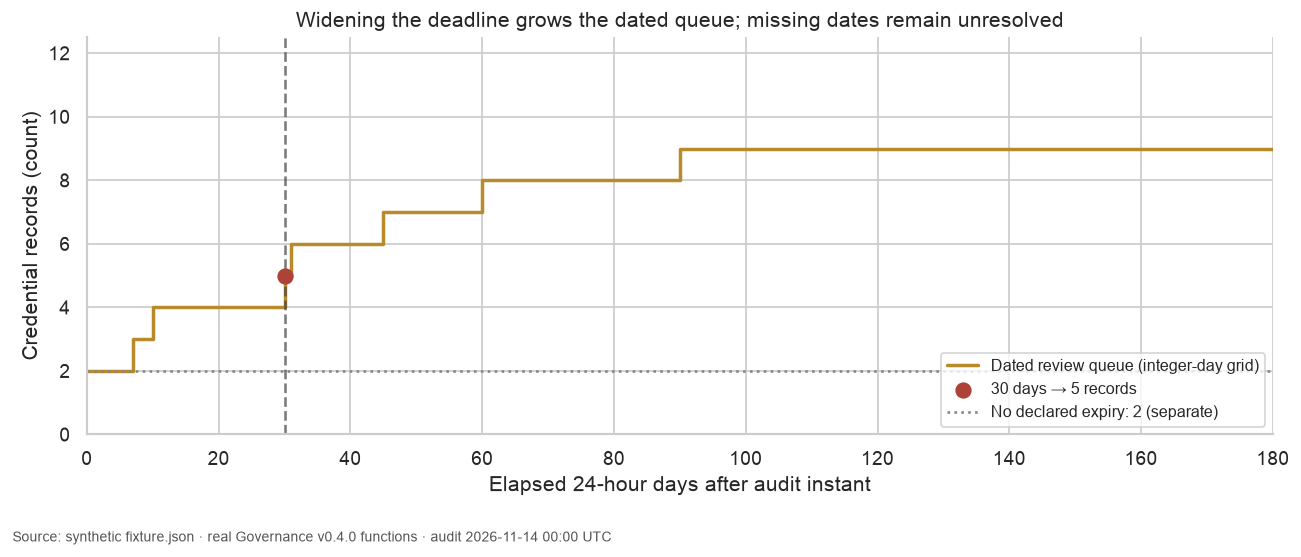

In [19]:
assert (sensitivity.dated_queue.diff().dropna()>=0).all()
fig,ax=plt.subplots(figsize=(10.5,4.7))
ax.step(sensitivity.horizon_days,sensitivity.dated_queue,where="post",color=COLORS["Due in horizon"],linewidth=2,label="Dated review queue (integer-day grid)")
ax.scatter([HORIZON_DAYS],[queue_count],color=COLORS["Past due"],s=70,zorder=3,label=f"{HORIZON_DAYS} days → {queue_count} records")
ax.axvline(HORIZON_DAYS,color="#444444",linestyle="--",alpha=.7)
ax.axhline(s.unknown,color=COLORS["No declared expiry"],linestyle=":",label=f"No declared expiry: {int(s.unknown)} (separate)")
ax.set(xlabel="Elapsed 24-hour days after audit instant",ylabel="Credential records (count)",
       xlim=(0,180),ylim=(0,int(s.total)+.5),title="Widening the deadline grows the dated queue; missing dates remain unresolved")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True));ax.legend(loc="lower right",fontsize=9);finish(fig)

## One change to test

Change only **`HORIZON_DAYS` from `30` to `60`** and execute a separate experiment copy. Predict a queue that is at least as large, with the same total inventory and missing-expiry count. Compare the owner bars and dated queue count. Keep `AS_OF_UTC` fixed and confirm the fixture hash matches.

The worker's scan-time day counters can change when rerun, even though the synthetic inventory and audit classifications stay fixed. That is the reason to preserve absolute dates and an explicit audit clock. Reset the horizon to **`30`** afterward; the [README](README.md) gives the separate-output command.

No live tenant, authentication path or actual credential validity is tested here. Missing dates, privilege, effective access, deployment dependencies and ownership decisions require additional context beyond this metadata inventory.

In [20]:
con.close()
fixture_secret_directory.cleanup()
scratch.cleanup()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and fixture design](README.md)